<img src="https://raw.githubusercontent.com/sokrypton/ColabFold/main/.github/ColabFold_Marv_Logo_Small.png" height="200" align="right" style="height:240px">

## ColabFold: AlphaFold2 using MMseqs2

Easy to use protein structure and complex prediction using [AlphaFold2](https://www.nature.com/articles/s41586-021-03819-2) and [Alphafold2-multimer](https://www.biorxiv.org/content/10.1101/2021.10.04.463034v1). Sequence alignments/templates are generated through [MMseqs2](https://mmseqs.com) and [HHsearch](https://github.com/soedinglab/hh-suite). For more details, see <a href="#Instructions">bottom</a> of the notebook, checkout the [ColabFold GitHub](https://github.com/sokrypton/ColabFold) and read our manuscript.
Old versions: [v1.4](https://colab.research.google.com/github/sokrypton/ColabFold/blob/v1.4.0/AlphaFold2.ipynb), [v1.5.1](https://colab.research.google.com/github/sokrypton/ColabFold/blob/v1.5.1/AlphaFold2.ipynb)

[Mirdita M, Schütze K, Moriwaki Y, Heo L, Ovchinnikov S, Steinegger M. ColabFold: Making protein folding accessible to all.
*Nature Methods*, 2022](https://www.nature.com/articles/s41592-022-01488-1)

**Before you start:** make sure the runtime has a GPU (`Runtime` -> `Change runtime type` -> `T4 GPU` or better), then hit `Runtime` -> `Run all`.

In [1]:
#@title Input protein sequence(s), then hit `Runtime` -> `Run all`
from google.colab import files
import os
import re
import hashlib

def add_hash(x,y):
  return x+"_"+hashlib.sha1(y.encode()).hexdigest()[:5]

query_sequence = 'PIAQIHILEGRSDEQKETLIREVSEAISRSLDAPLTSVRVIITEMAKGHFGIGGELASK' #@param {type:"string"}
#@markdown  - Use `:` to specify inter-protein chainbreaks for **modeling complexes** (supports homo- and hetro-oligomers). For example **PI...SK:PI...SK** for a homodimer
jobname = 'test' #@param {type:"string"}
# number of models to use
num_relax = 0 #@param [0, 1, 5] {type:"raw"}
#@markdown - specify how many of the top ranked structures to relax using amber
template_mode = "none" #@param ["none", "pdb100","custom"]
#@markdown - `none` = no template information is used. `pdb100` = detect templates in pdb100 (see [notes](#pdb100)). `custom` - upload and search own templates (PDB or mmCIF format, see [notes](#custom_templates))

use_amber = num_relax > 0

# remove whitespaces
query_sequence = "".join(query_sequence.split())

basejobname = "".join(jobname.split())
basejobname = re.sub(r'\W+', '', basejobname)
jobname = add_hash(basejobname, query_sequence)

# check if directory with jobname exists
def check(folder):
  if os.path.exists(folder):
    return False
  else:
    return True
if not check(jobname):
  n = 0
  while not check(f"{jobname}_{n}"): n += 1
  jobname = f"{jobname}_{n}"

# make directory to save results
os.makedirs(jobname, exist_ok=True)

# save queries
queries_path = os.path.join(jobname, f"{jobname}.csv")
with open(queries_path, "w") as text_file:
  text_file.write(f"id,sequence\n{jobname},{query_sequence}")

if template_mode == "pdb100":
  use_templates = True
  custom_template_path = None
elif template_mode == "custom":
  custom_template_path = os.path.join(jobname,f"template")
  os.makedirs(custom_template_path, exist_ok=True)
  uploaded = files.upload()
  use_templates = True
  for fn in uploaded.keys():
    os.rename(fn,os.path.join(custom_template_path,fn))
else:
  custom_template_path = None
  use_templates = False

print("jobname",jobname)
print("sequence",query_sequence)
print("length",len(query_sequence.replace(":","")))

jobname test_a5e17
sequence PIAQIHILEGRSDEQKETLIREVSEAISRSLDAPLTSVRVIITEMAKGHFGIGGELASK
length 59


In [2]:
#@title Install dependencies
import os
import subprocess
import sys

USE_AMBER = use_amber
USE_TEMPLATES = use_templates

def sh(cmd, msg=None, check=True):
  """Run a shell command; show its output only if it fails."""
  if msg:
    print(msg)
  r = subprocess.run(cmd, shell=True, executable="/bin/bash",
                     capture_output=True, text=True)
  if r.returncode != 0:
    print(r.stdout[-4000:])
    print(r.stderr[-4000:])
    if check:
      raise RuntimeError(f"Command failed: {cmd}")
  return r

# ---- check for a GPU ------------------------------------------------------
gpu = subprocess.run(
  "nvidia-smi --query-gpu=name,memory.total --format=csv,noheader",
  shell=True, capture_output=True, text=True)
has_gpu = gpu.returncode == 0 and gpu.stdout.strip() != ""
if has_gpu:
  print("GPU:", gpu.stdout.strip())
else:
  print("WARNING: no GPU found! Use `Runtime` -> `Change runtime type` and select a GPU "
        "(e.g. T4), then run all cells again. Predictions on CPU are extremely slow.")

# ---- colabfold ---------------------------------------------------------------
# Colab already ships with a CUDA build of jax, so we install the "-minus-jax" extra
# and leave the preinstalled jax/numpy alone. "--no-warn-conflicts" is used because
# Colab has many preinstalled packages with requirements different to ours.
if not os.path.isfile("COLABFOLD_READY"):
  sh("pip install -q --no-warn-conflicts "
     "'colabfold[alphafold-minus-jax] @ git+https://github.com/sokrypton/ColabFold'",
     "installing colabfold...")

  # make sure jax can actually see the GPU (fall back to installing a CUDA build)
  if has_gpu:
    r = sh(f'{sys.executable} -c "import jax; print(jax.default_backend())"', check=False)
    if "gpu" not in r.stdout and "cuda" not in r.stdout:
      sh("pip install -q -U 'jax[cuda12]'", "installing GPU version of jax...")
  open("COLABFOLD_READY", "w").close()

# ---- amber relaxation (openmm + pdbfixer from PyPI) ---------------------------
if USE_AMBER and not os.path.isfile("AMBER_READY"):
  sh("pip install -q --no-warn-conflicts 'openmm>=8.5,<9' 'pdbfixer>=1.12,<2'",
     "installing amber (openmm)...")
  # optional: CUDA plugin so relaxation runs on the GPU (relaxation still works on CPU without it)
  if has_gpu:
    sh("pip install -q --no-warn-conflicts 'openmm[cuda12]'", check=False)
  open("AMBER_READY", "w").close()

# ---- template search (kalign2 + hhsuite from conda-forge/bioconda) ------------
if USE_TEMPLATES and not os.path.isfile("HH_READY"):
  if not os.path.isfile("CONDA_READY"):
    sh("wget -qnc https://github.com/conda-forge/miniforge/releases/latest/download/Miniforge3-Linux-x86_64.sh "
       "&& bash Miniforge3-Linux-x86_64.sh -bfp /opt/conda && rm -f Miniforge3-Linux-x86_64.sh",
       "installing conda...")
    open("CONDA_READY", "w").close()
  sh("/opt/conda/bin/conda install -y -q -c conda-forge -c bioconda kalign2=2.04 hhsuite=3.3.0",
     "installing hhsuite...")
  # expose only the needed binaries, so conda's python never shadows Colab's python
  for b in ["kalign", "hhsearch", "hhblits", "hhmake", "hhfilter", "hhalign"]:
    sh(f"[ -e /opt/conda/bin/{b} ] && ln -sf /opt/conda/bin/{b} /usr/local/bin/{b} || true", check=False)
  open("HH_READY", "w").close()

print("dependencies ready")

GPU: Tesla T4, 15360 MiB
installing colabfold...
dependencies ready


In [3]:
#@markdown ### MSA options (custom MSA upload, single sequence, pairing mode)
msa_mode = "mmseqs2_uniref_env" #@param ["mmseqs2_uniref_env", "mmseqs2_uniref","single_sequence","custom"]
pair_mode = "unpaired_paired" #@param ["unpaired_paired","paired","unpaired"] {type:"string"}
#@markdown - "unpaired_paired" = pair sequences from same species + unpaired MSA, "unpaired" = separate MSA for each chain, "paired" - only use paired sequences.

# decide which a3m to use
if "mmseqs2" in msa_mode:
  a3m_file = os.path.join(jobname,f"{jobname}.a3m")

elif msa_mode == "custom":
  a3m_file = os.path.join(jobname,f"{jobname}.custom.a3m")
  if not os.path.isfile(a3m_file):
    custom_msa_dict = files.upload()
    custom_msa = list(custom_msa_dict.keys())[0]
    header = 0
    import fileinput
    for line in fileinput.FileInput(custom_msa,inplace=1):
      if line.startswith(">"):
         header = header + 1
      if not line.rstrip():
        continue
      if line.startswith(">") == False and header == 1:
         query_sequence = line.rstrip()
      print(line, end='')

    os.rename(custom_msa, a3m_file)
    queries_path=a3m_file
    print(f"moving {custom_msa} to {a3m_file}")

else:
  a3m_file = os.path.join(jobname,f"{jobname}.single_sequence.a3m")
  with open(a3m_file, "w") as text_file:
    text_file.write(">1\n%s" % query_sequence)

In [4]:
#@markdown ### Advanced settings
model_type = "auto" #@param ["auto", "alphafold2_ptm", "alphafold2_multimer_v1", "alphafold2_multimer_v2", "alphafold2_multimer_v3"]
#@markdown - if `auto` selected, will use `alphafold2_ptm` for monomer prediction and `alphafold2_multimer_v3` for complex prediction.
#@markdown Any of the mode_types can be used (regardless if input is monomer or complex).
num_recycles = "auto" #@param ["auto", "0", "1", "3", "6", "12", "24", "48"]
recycle_early_stop_tolerance = "auto" #@param ["auto", "0.0", "0.5", "1.0"]
#@markdown - if `auto` selected, will use 20 recycles if `model_type=alphafold2_multimer_v3` (with tol=0.5), all else 3 recycles (with tol=0.0).
pairing_strategy = "greedy" #@param ["greedy", "complete"] {type:"string"}
#@markdown - `greedy` = pair any taxonomically matching subsets, `complete` = all sequences have to match in one line.

#@markdown #### Sample settings
#@markdown -  enable dropouts and increase number of seeds to sample predictions from uncertainty of the model.
#@markdown -  decrease `max_msa` to increase uncertainity
max_msa = "auto" #@param ["auto", "512:1024", "256:512", "64:128", "32:64", "16:32"]
num_seeds = 1 #@param [1,2,4,8,16] {type:"raw"}
use_dropout = False #@param {type:"boolean"}

num_recycles = None if num_recycles == "auto" else int(num_recycles)
recycle_early_stop_tolerance = None if recycle_early_stop_tolerance == "auto" else float(recycle_early_stop_tolerance)
if max_msa == "auto": max_msa = None

#@markdown #### Save settings
save_all = False #@param {type:"boolean"}
save_recycles = False #@param {type:"boolean"}
save_to_google_drive = False #@param {type:"boolean"}
#@markdown -  if the save_to_google_drive option was selected, the result zip will be copied to `MyDrive/ColabFold` in your Google Drive
dpi = 200 #@param {type:"integer"}
#@markdown - set dpi for image resolution

if save_to_google_drive:
  from google.colab import drive
  drive.mount('/content/drive')
  print("Google Drive is mounted and good to go!")

#@markdown Don't forget to hit `Runtime` -> `Run all` after updating the form.

2026-11-10 23:08:31,859 Running on GPU
2026-11-10 23:08:32,349 Found 5 citations for tools or databases
2026-11-10 23:08:32,350 Query 1/1: test_a5e17 (length 59)
2026-11-10 23:08:32,350 No user agent specified. Please set a user agent (e.g., 'toolname/version contact@email') to help us debug in case of problems. This warning will become an error in the future.


COMPLETE: 100%|██████████| 150/150 [elapsed: 00:01 remaining: 00:00]


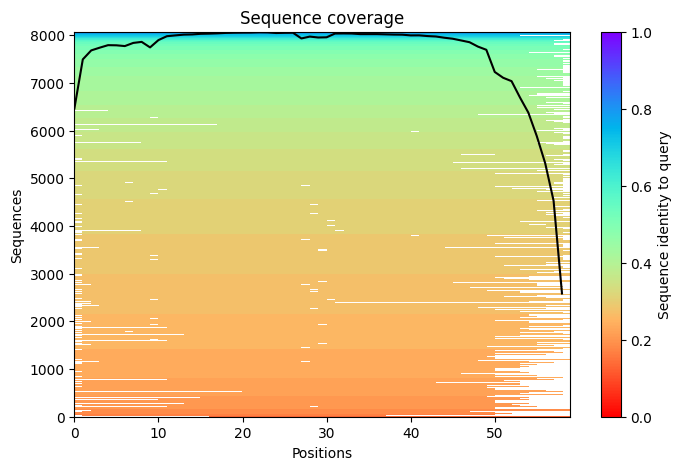

2026-11-10 23:08:35,251 Setting max_seq=512, max_extra_seq=5120
2026-11-10 23:09:18,233 alphafold2_ptm_model_1_seed_000 recycle=0 pLDDT=96.6 pTM=0.753
2026-11-10 23:09:21,431 alphafold2_ptm_model_1_seed_000 recycle=1 pLDDT=96.4 pTM=0.757 tol=0.235
2026-11-10 23:09:24,643 alphafold2_ptm_model_1_seed_000 recycle=2 pLDDT=96.1 pTM=0.753 tol=0.0833
2026-11-10 23:09:27,868 alphafold2_ptm_model_1_seed_000 recycle=3 pLDDT=95.5 pTM=0.75 tol=0.0729
2026-11-10 23:09:27,869 alphafold2_ptm_model_1_seed_000 took 44.5s (3 recycles)


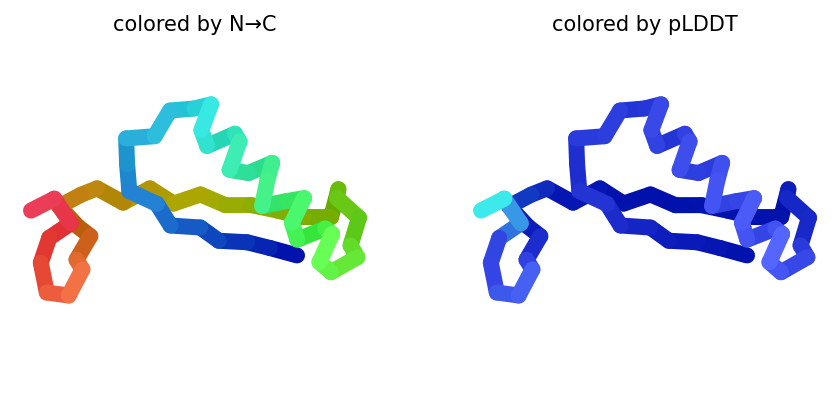

2026-11-10 23:09:31,276 alphafold2_ptm_model_2_seed_000 recycle=0 pLDDT=96.9 pTM=0.761
2026-11-10 23:09:34,515 alphafold2_ptm_model_2_seed_000 recycle=1 pLDDT=97 pTM=0.767 tol=0.312
2026-11-10 23:09:37,760 alphafold2_ptm_model_2_seed_000 recycle=2 pLDDT=96.7 pTM=0.762 tol=0.149
2026-11-10 23:09:41,009 alphafold2_ptm_model_2_seed_000 recycle=3 pLDDT=96.5 pTM=0.763 tol=0.0381
2026-11-10 23:09:41,011 alphafold2_ptm_model_2_seed_000 took 13.0s (3 recycles)


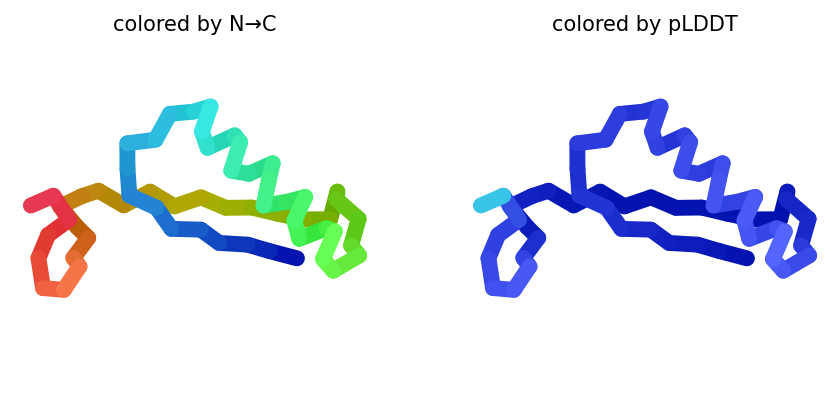

2026-11-10 23:09:44,414 alphafold2_ptm_model_3_seed_000 recycle=0 pLDDT=97.2 pTM=0.775
2026-11-10 23:09:47,672 alphafold2_ptm_model_3_seed_000 recycle=1 pLDDT=97.4 pTM=0.783 tol=0.227
2026-11-10 23:09:50,939 alphafold2_ptm_model_3_seed_000 recycle=2 pLDDT=97.4 pTM=0.782 tol=0.0942
2026-11-10 23:09:54,210 alphafold2_ptm_model_3_seed_000 recycle=3 pLDDT=97.4 pTM=0.782 tol=0.0554
2026-11-10 23:09:54,211 alphafold2_ptm_model_3_seed_000 took 13.1s (3 recycles)


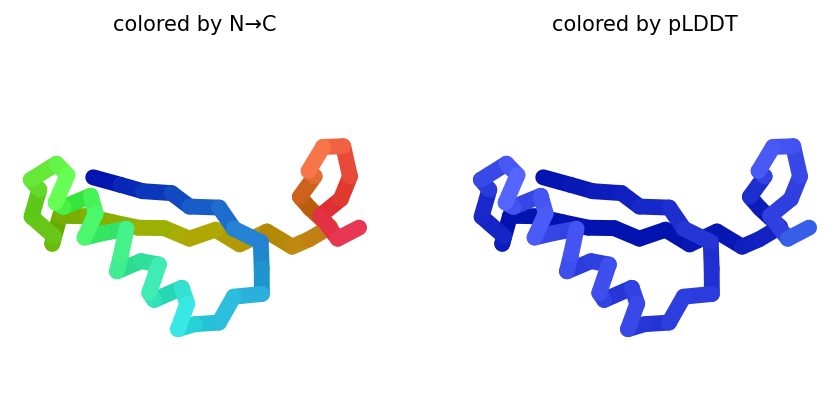

2026-11-10 23:09:57,655 alphafold2_ptm_model_4_seed_000 recycle=0 pLDDT=97.2 pTM=0.772
2026-11-10 23:10:00,955 alphafold2_ptm_model_4_seed_000 recycle=1 pLDDT=97.2 pTM=0.778 tol=0.229
2026-11-10 23:10:04,261 alphafold2_ptm_model_4_seed_000 recycle=2 pLDDT=96.9 pTM=0.776 tol=0.0648
2026-11-10 23:10:07,574 alphafold2_ptm_model_4_seed_000 recycle=3 pLDDT=96.6 pTM=0.775 tol=0.071
2026-11-10 23:10:07,575 alphafold2_ptm_model_4_seed_000 took 13.2s (3 recycles)


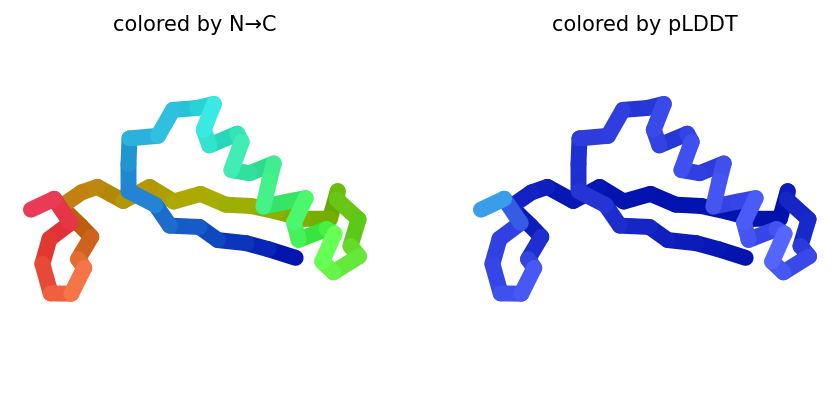

2026-11-10 23:10:11,060 alphafold2_ptm_model_5_seed_000 recycle=0 pLDDT=97 pTM=0.781
2026-11-10 23:10:14,426 alphafold2_ptm_model_5_seed_000 recycle=1 pLDDT=96.4 pTM=0.781 tol=0.27
2026-11-10 23:10:17,810 alphafold2_ptm_model_5_seed_000 recycle=2 pLDDT=96.2 pTM=0.778 tol=0.187
2026-11-10 23:10:21,220 alphafold2_ptm_model_5_seed_000 recycle=3 pLDDT=96.2 pTM=0.777 tol=0.0951
2026-11-10 23:10:21,221 alphafold2_ptm_model_5_seed_000 took 13.5s (3 recycles)


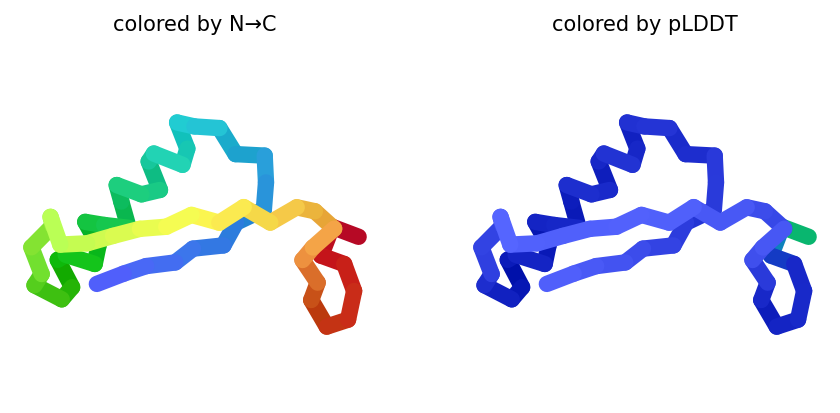

2026-11-10 23:10:21,365 reranking models by 'plddt' metric
2026-11-10 23:10:21,365 rank_001_alphafold2_ptm_model_3_seed_000 pLDDT=97.4 pTM=0.782
2026-11-10 23:10:21,366 rank_002_alphafold2_ptm_model_4_seed_000 pLDDT=96.6 pTM=0.775
2026-11-10 23:10:21,366 rank_003_alphafold2_ptm_model_2_seed_000 pLDDT=96.5 pTM=0.763
2026-11-10 23:10:21,366 rank_004_alphafold2_ptm_model_5_seed_000 pLDDT=96.2 pTM=0.777
2026-11-10 23:10:21,367 rank_005_alphafold2_ptm_model_1_seed_000 pLDDT=95.5 pTM=0.75
2026-11-10 23:10:22,840 Done
created test_a5e17.result.zip


In [5]:
#@title Run Prediction
display_images = True #@param {type:"boolean"}

import os
import sys
import shutil
import warnings
warnings.simplefilter(action='ignore', category=FutureWarning)
try:
  from Bio import BiopythonDeprecationWarning
  warnings.simplefilter(action='ignore', category=BiopythonDeprecationWarning)
except ImportError:
  pass

# Cache compiled JAX programs on disk: re-running with the same sequence length
# and MSA depth in the same session then skips the (slow) recompilation.
os.environ.setdefault("JAX_COMPILATION_CACHE_DIR", os.path.abspath("jax_cache"))

from pathlib import Path
from colabfold.download import download_alphafold_params, default_data_dir
from colabfold.utils import setup_logging
from colabfold.batch import get_queries, run, set_model_type
from colabfold.plot import plot_msa_v2
from colabfold.colabfold import plot_protein
import numpy as np
import matplotlib.pyplot as plt

def input_features_callback(input_features):
  if display_images:
    plot_msa_v2(input_features)
    plt.show()
    plt.close()

def prediction_callback(protein_obj, length,
                        prediction_result, input_features, mode):
  _model_name, relaxed = mode
  if not relaxed:
    if display_images:
      plot_protein(protein_obj, Ls=length, dpi=150)
      plt.show()
      plt.close()

result_dir = jobname
jobname_prefix = ".custom" if msa_mode == "custom" else ""
if 'logging_setup' not in globals():
    setup_logging(Path(os.path.join(jobname,"log.txt")))
    logging_setup = True

queries, is_complex = get_queries(queries_path)
model_type = set_model_type(is_complex, model_type)

if "multimer" in model_type and max_msa is not None:
  use_cluster_profile = False
else:
  use_cluster_profile = True

download_alphafold_params(model_type, Path("."))
results = run(
    queries=queries,
    result_dir=result_dir,
    use_templates=use_templates,
    custom_template_path=custom_template_path,
    num_relax=num_relax,
    msa_mode=msa_mode,
    model_type=model_type,
    num_models=5,
    num_recycles=num_recycles,
    recycle_early_stop_tolerance=recycle_early_stop_tolerance,
    num_seeds=num_seeds,
    use_dropout=use_dropout,
    model_order=[1,2,3,4,5],
    is_complex=is_complex,
    data_dir=Path("."),
    keep_existing_results=False,
    rank_by="auto",
    pair_mode=pair_mode,
    pairing_strategy=pairing_strategy,
    stop_at_score=float(100),
    prediction_callback=prediction_callback,
    dpi=dpi,
    zip_results=False,
    save_all=save_all,
    max_msa=max_msa,
    use_cluster_profile=use_cluster_profile,
    input_features_callback=input_features_callback,
    save_recycles=save_recycles,
)
results_zip = f"{jobname}.result.zip"
shutil.make_archive(f"{jobname}.result", "zip", root_dir=".", base_dir=jobname)
print("created", results_zip)

3Dmol.js failed to load for some reason. Please check your browser console for error messages.

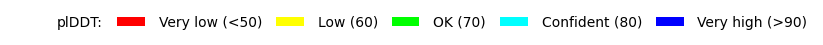

In [6]:
#@title Display 3D structure {run: "auto"}
import py3Dmol
import glob
import matplotlib.pyplot as plt
from colabfold.colabfold import plot_plddt_legend
from colabfold.colabfold import pymol_color_list, alphabet_list
rank_num = 1 #@param ["1", "2", "3", "4", "5"] {type:"raw"}
color = "lDDT" #@param ["chain", "lDDT", "rainbow"]
show_sidechains = False #@param {type:"boolean"}
show_mainchains = False #@param {type:"boolean"}

tag = results["rank"][0][rank_num - 1]
pdb_filename = f"{jobname}/{jobname}{jobname_prefix}_unrelaxed_{tag}.pdb"
pdb_file = glob.glob(pdb_filename)

def show_pdb(rank_num=1, show_sidechains=False, show_mainchains=False, color="lDDT"):
  view = py3Dmol.view(js='https://3dmol.org/build/3Dmol.js',)
  view.addModel(open(pdb_file[0],'r').read(),'pdb')

  if color == "lDDT":
    view.setStyle({'cartoon': {'colorscheme': {'prop':'b','gradient': 'roygb','min':50,'max':90}}})
  elif color == "rainbow":
    view.setStyle({'cartoon': {'color':'spectrum'}})
  elif color == "chain":
    chains = len(queries[0][1]) + 1 if is_complex else 1
    for n,chain,color in zip(range(chains),alphabet_list,pymol_color_list):
       view.setStyle({'chain':chain},{'cartoon': {'color':color}})

  if show_sidechains:
    BB = ['C','O','N']
    view.addStyle({'and':[{'resn':["GLY","PRO"],'invert':True},{'atom':BB,'invert':True}]},
                        {'stick':{'colorscheme':f"WhiteCarbon",'radius':0.3}})
    view.addStyle({'and':[{'resn':"GLY"},{'atom':'CA'}]},
                        {'sphere':{'colorscheme':f"WhiteCarbon",'radius':0.3}})
    view.addStyle({'and':[{'resn':"PRO"},{'atom':['C','O'],'invert':True}]},
                        {'stick':{'colorscheme':f"WhiteCarbon",'radius':0.3}})
  if show_mainchains:
    BB = ['C','O','N','CA']
    view.addStyle({'atom':BB},{'stick':{'colorscheme':f"WhiteCarbon",'radius':0.3}})

  view.zoomTo()
  return view

show_pdb(rank_num, show_sidechains, show_mainchains, color).show()
if color == "lDDT":
  plot_plddt_legend().show()


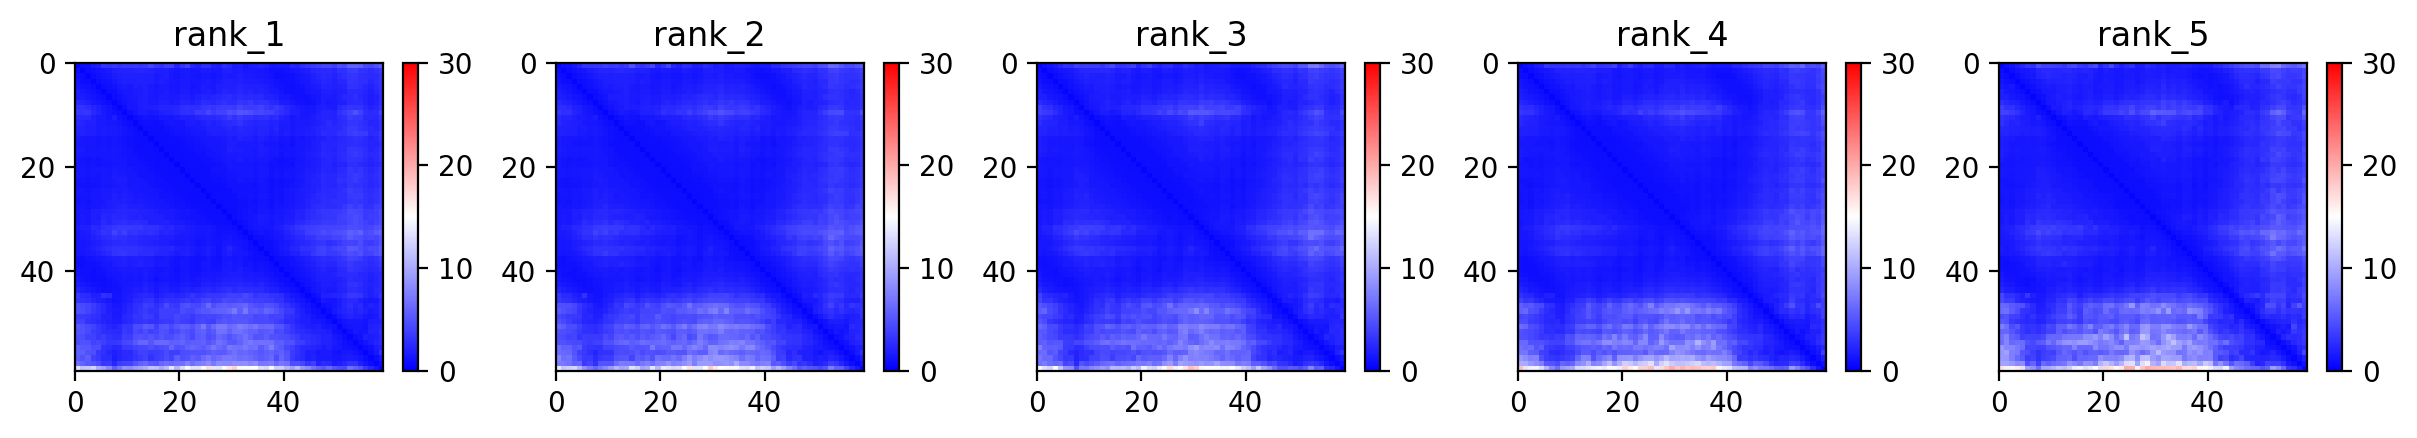
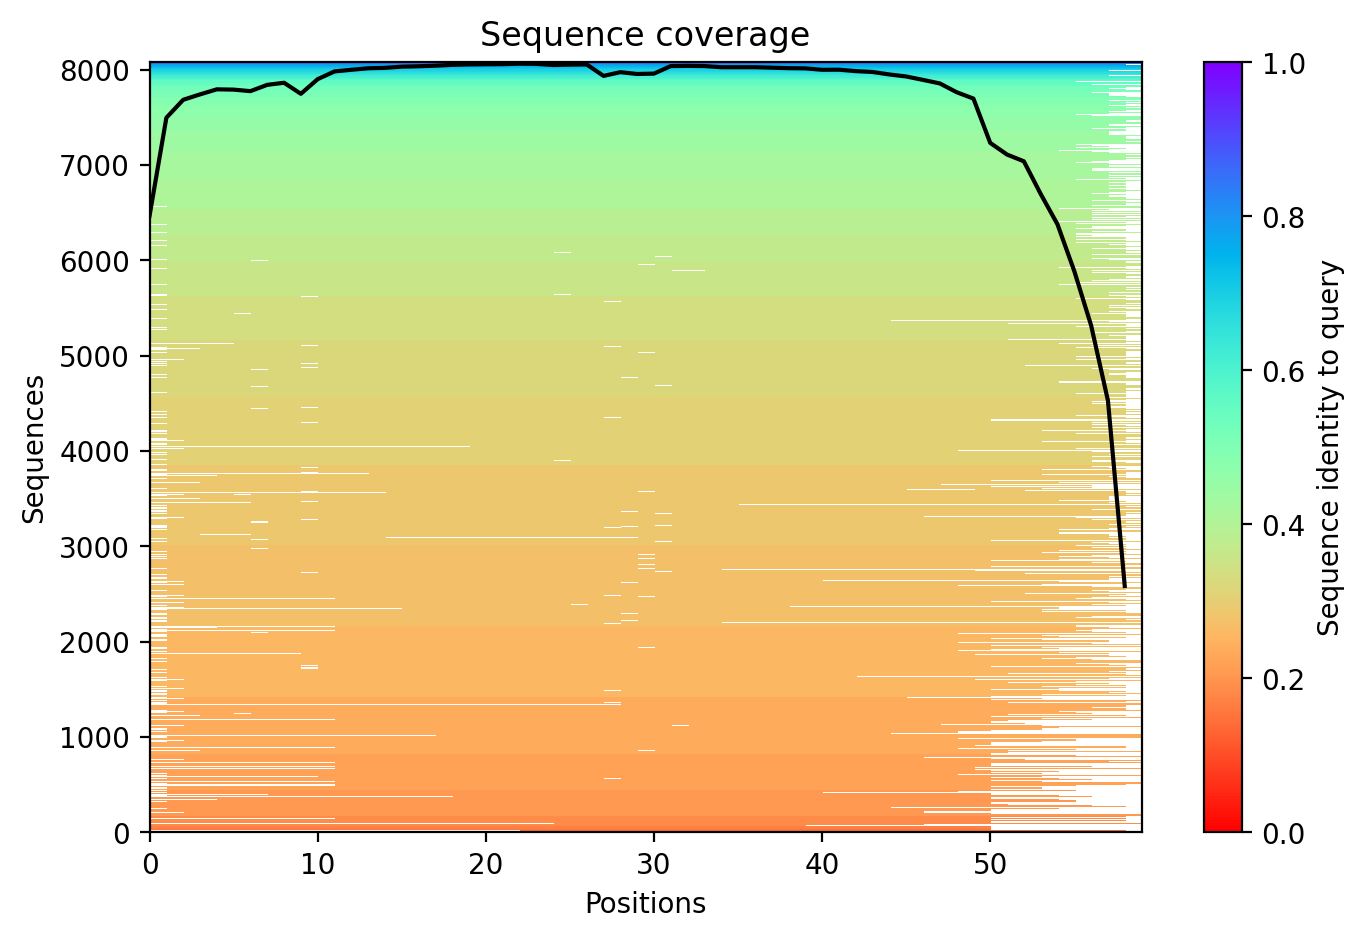
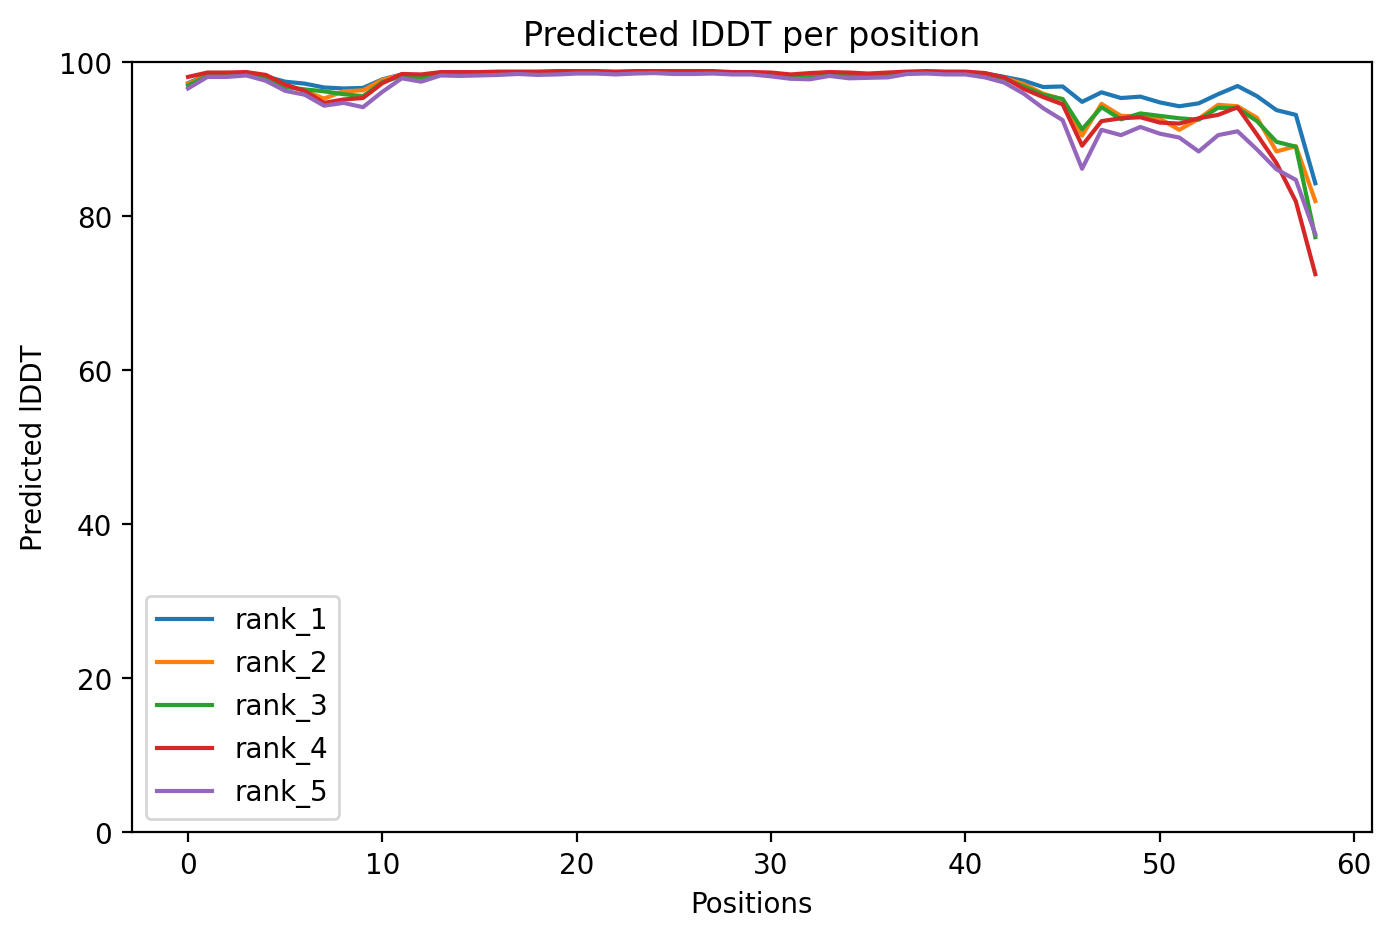

In [7]:
#@title Plots {run: "auto"}
from IPython.display import display, HTML
import base64
from html import escape

# see: https://stackoverflow.com/a/53688522
def image_to_data_url(filename):
  ext = filename.split('.')[-1]
  prefix = f'data:image/{ext};base64,'
  with open(filename, 'rb') as f:
    img = f.read()
  return prefix + base64.b64encode(img).decode('utf-8')

pae = image_to_data_url(os.path.join(jobname,f"{jobname}{jobname_prefix}_pae.png"))
cov = image_to_data_url(os.path.join(jobname,f"{jobname}{jobname_prefix}_coverage.png"))
plddt = image_to_data_url(os.path.join(jobname,f"{jobname}{jobname_prefix}_plddt.png"))
display(HTML(f"""
<style>
  img {{
    float:left;
  }}
  .full {{
    max-width:100%;
  }}
  .half {{
    max-width:50%;
  }}
  @media (max-width:640px) {{
    .half {{
      max-width:100%;
    }}
  }}
</style>
<div style="max-width:90%; padding:2em;">
  <h1>Plots for {escape(jobname)}</h1>
  <img src="{pae}" class="full" />
  <img src="{cov}" class="half" />
  <img src="{plddt}" class="half" />
</div>
"""))


In [8]:
#@title Package and download results
#@markdown If you are having issues downloading the result archive, try disabling your adblocker and run this cell again. If that fails click on the little folder icon to the left, navigate to file: `jobname.result.zip`, right-click and select \"Download\" (see [screenshot](https://pbs.twimg.com/media/E6wRW2lWUAEOuoe?format=jpg&name=small)).
import shutil

if msa_mode == "custom":
  print("Don't forget to cite your custom MSA generation method.")

if save_to_google_drive:
  drive_dir = "/content/drive/MyDrive/ColabFold"
  os.makedirs(drive_dir, exist_ok=True)
  shutil.copy(f"{jobname}.result.zip", drive_dir)
  print(f"Copied {jobname}.result.zip to {drive_dir} (Google Drive: MyDrive/ColabFold)")

try:
  files.download(f"{jobname}.result.zip")
except Exception as e:
  print("Automatic download failed:", e)
  print(f"Use the folder icon on the left to download {jobname}.result.zip manually.")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

# Instructions <a name="Instructions"></a>
**Quick start**
1. Paste your protein sequence(s) in the input field.
2. Press "Runtime" -> "Run all".
3. The pipeline consists of 5 steps. The currently running step is indicated by a circle with a stop sign next to it.

**Result zip file contents**

1. PDB formatted structures sorted by avg. pLDDT and complexes are sorted by pTMscore. (unrelaxed and relaxed if `use_amber` is enabled).
2. Plots of the model quality.
3. Plots of the MSA coverage.
4. Parameter log file.
5. A3M formatted input MSA.
6. A `predicted_aligned_error_v1.json` using [AlphaFold-DB's format](https://alphafold.ebi.ac.uk/faq#faq-7) and a `scores.json` for each model which contains an array (list of lists) for PAE, a list with the average pLDDT and the pTMscore.
7. BibTeX file with citations for all used tools and databases.

At the end of the job a download modal box will pop up with a `jobname.result.zip` file. Additionally, if the `save_to_google_drive` option was selected, Google Drive is mounted and `jobname.result.zip` is copied to the `ColabFold` folder in your My Drive.

**MSA generation for complexes**

For the complex prediction we use unpaired and paired MSAs. Unpaired MSA is generated the same way as for the protein structures prediction by searching the UniRef100 and environmental sequences three iterations each.

The paired MSA is generated by searching the UniRef100 database and pairing the best hits sharing the same NCBI taxonomic identifier (=species or sub-species). With `pairing_strategy = greedy` (default) any taxonomically matching subset of the chains is paired; with `complete` we only pair sequences if all of the query sequences are present for the respective taxonomic identifier.

**Using a custom MSA as input**

To predict the structure with a custom MSA (A3M formatted): (1) Change the `msa_mode`: to "custom", (2) Wait for an upload box to appear at the end of the "MSA options ..." box. Upload your A3M. The first fasta entry of the A3M must be the query sequence without gaps.

It is also possible to provide custom MSAs for complex predictions. Read more about the format [here](https://github.com/sokrypton/ColabFold/issues/76).

As an alternative for MSA generation the [HHblits Toolkit server](https://toolkit.tuebingen.mpg.de/tools/hhblits) can be used. After submitting your query, click "Query Template MSA" -> "Download Full A3M". Download the A3M file and upload it in this notebook.

**PDB100** <a name="pdb100"></a>

Template search uses a 100% clustered PDB (PDB100) rather than the older PDB70. The PDB100 is built by searching each representative structure with [Foldseek](https://github.com/steineggerlab/foldseek) against the [AlphaFold Database](https://alphafold.ebi.ac.uk). For compatibility, generated files and API responses are still named "PDB70".

**Using custom templates** <a name="custom_templates"></a>

To predict the structure with a custom template (PDB or mmCIF formatted): (1) change the `template_mode` to "custom" in the execute cell and (2) wait for an upload box to appear at the end of the "Input Protein" box. Select and upload your templates (multiple choices are possible).

* Templates must follow the four letter PDB naming with lower case letters.

* Templates in mmCIF format must contain `_entity_poly_seq`. An error is thrown if this field is not present. The field `_pdbx_audit_revision_history.revision_date` is automatically generated if it is not present.

* Templates in PDB format are automatically converted to the mmCIF format. `_entity_poly_seq` and `_pdbx_audit_revision_history.revision_date` are automatically generated.

If you encounter problems, please report them to this [issue](https://github.com/sokrypton/ColabFold/issues/177).

**Comparison to the full AlphaFold2 and Alphafold2 colab**

This notebook replaces the homology detection and MSA pairing of AlphaFold2 with MMseqs2. For a comparison against the [AlphaFold2 Colab](https://colab.research.google.com/github/deepmind/alphafold/blob/main/notebooks/AlphaFold.ipynb) and the full [AlphaFold2](https://github.com/deepmind/alphafold) system read our [preprint](https://www.biorxiv.org/content/10.1101/2021.08.15.456425v1).

**Troubleshooting**
* Check that the runtime type is set to GPU at "Runtime" -> "Change runtime type".
* If the prediction cell fails with an import / numpy / binary-compatibility error right after the install cell, do "Runtime" -> "Restart session" and "Run all" again. Installation is remembered (`COLABFOLD_READY` etc.) and will not be repeated.
* Try to restart the session "Runtime" -> "Factory reset runtime".
* Check your input sequence.

**Known issues**
* Google Colab assigns different types of GPUs with varying amount of memory (free tier: usually a T4 with ~15 GB, roughly enough for ~2000 residues). Some might not have enough memory to predict the structure for a long sequence.
* Files in the Colab session (including the install markers and downloaded model parameters) are lost when the runtime is recycled; use `save_to_google_drive` or download the zip before closing the session.
* Your browser can block the pop-up for downloading the result file. You can choose the `save_to_google_drive` option to upload to Google Drive instead or manually download the result file: Click on the little folder icon to the left, navigate to file: `jobname.result.zip`, right-click and select \"Download\" (see [screenshot](https://pbs.twimg.com/media/E6wRW2lWUAEOuoe?format=jpg&name=small)).

**Limitations**
* Computing resources: Our MMseqs2 API can handle ~20-50k requests per day.
* MSAs: MMseqs2 is very precise and sensitive but might find less hits compared to HHblits/HMMer searched against BFD or MGnify.
* We recommend to additionally use the full [AlphaFold2 pipeline](https://github.com/deepmind/alphafold).

**Description of the plots**
*   **Number of sequences per position** - We want to see at least 30 sequences per position, for best performance, ideally 100 sequences.
*   **Predicted lDDT per position** - model confidence (out of 100) at each position. The higher the better.
*   **Predicted Alignment Error** - For homooligomers, this could be a useful metric to assess how confident the model is about the interface. The lower the better.

**Bugs**
- If you encounter any bugs, please report the issue to https://github.com/sokrypton/ColabFold/issues

**License**

The source code of ColabFold is licensed under [MIT](https://raw.githubusercontent.com/sokrypton/ColabFold/main/LICENSE). Additionally, this notebook uses the AlphaFold2 source code and its parameters licensed under [Apache 2.0](https://raw.githubusercontent.com/deepmind/alphafold/main/LICENSE) and [CC BY 4.0](https://creativecommons.org/licenses/by-sa/4.0/) respectively. Read more about the AlphaFold license [here](https://github.com/deepmind/alphafold).

**Acknowledgments**
- We thank the AlphaFold team for developing an excellent model and open sourcing the software.

- [KOBIC](https://kobic.re.kr) and [Söding Lab](https://www.mpinat.mpg.de/soeding) for providing the computational resources for the MMseqs2 MSA server.

- Richard Evans for helping to benchmark the ColabFold's Alphafold-multimer support.

- [David Koes](https://github.com/dkoes) for his awesome [py3Dmol](https://3dmol.csb.pitt.edu/) plugin, without whom these notebooks would be quite boring!

- Do-Yoon Kim for creating the ColabFold logo.

- A colab by Sergey Ovchinnikov ([@sokrypton](https://twitter.com/sokrypton)), Milot Mirdita ([@milot_mirdita](https://twitter.com/milot_mirdita)) and Martin Steinegger ([@thesteinegger](https://twitter.com/thesteinegger)).